# Lab 2: Decision trees

In [1]:
import pandas as pd
from sklearn import tree
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt

weather = pd.read_csv("./weather.txt")

In [2]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

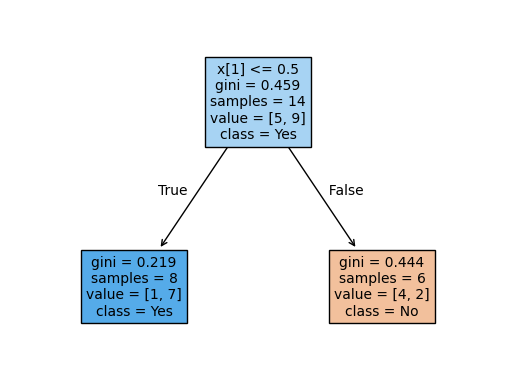

In [3]:
encoder.fit(weather.loc[:, ['Outlook']])
transformedOutlook = encoder.transform(weather.loc[:, ['Outlook']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformedOutlook, weather.loc[:, 'Play'])
fig = plt.figure()
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.show()

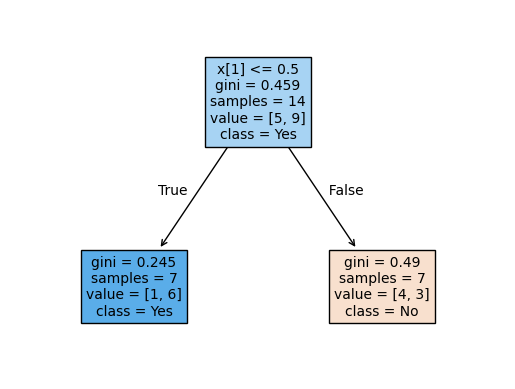

In [4]:
encoder.fit(weather.loc[:, ['Temperature']])
transformedTemperature = encoder.transform(weather.loc[:, ['Temperature']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformedTemperature, weather.loc[:, 'Play'])
fig = plt.figure()
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.show()

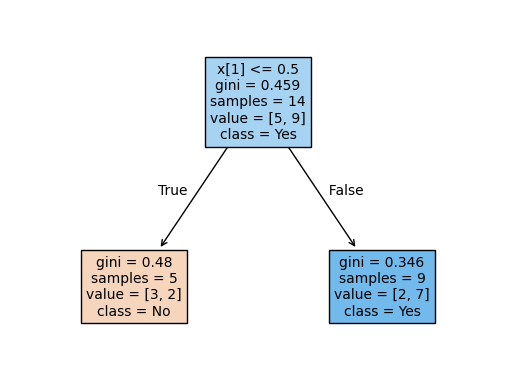

In [5]:
encoder.fit(weather.loc[:, ['Humidity']])
transformedHumidity = encoder.transform(weather.loc[:, ['Humidity']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformedHumidity, weather.loc[:, 'Play'])
fig = plt.figure()
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.show()

In [6]:
absfreq = pd.crosstab(weather.Outlook, weather.Play)
freq = pd.crosstab(weather.Outlook, weather.Play, normalize='index')
freqSum = pd.crosstab(weather.Outlook, weather.Play, normalize='all').sum(axis=1)
GINI_Sunny = 1 - freq.loc["Sunny", "No"]**2 - freq.loc["Sunny", "Yes"]**2
GINI_Rainy = 1 - freq.loc["Rainy", "No"]**2 - freq.loc["Rainy", "Yes"]**2
GINI_Outlook = freqSum.loc["Sunny"] * GINI_Sunny + freqSum["Rainy"] * GINI_Rainy
print(GINI_Outlook)

0.31547619047619047


In [7]:
absfreq = pd.crosstab(weather.Temperature, weather.Play)
freq = pd.crosstab(weather.Temperature, weather.Play, normalize='index')
freqSum = pd.crosstab(weather.Temperature, weather.Play, normalize='all').sum(axis=1)
GINI_Hot = 1 - freq.loc["Hot", "No"]**2 - freq.loc["Hot", "Yes"]**2
GINI_Cool = 1 - freq.loc["Cool", "No"]**2 - freq.loc["Cool", "Yes"]**2
GINI_Temperature = freqSum.loc["Hot"] * GINI_Hot + freqSum["Cool"] * GINI_Cool
print(GINI_Temperature)

0.3673469387755103


In [8]:
absfreq = pd.crosstab(weather.Humidity, weather.Play)
freq = pd.crosstab(weather.Humidity, weather.Play, normalize='index')
freqSum = pd.crosstab(weather.Humidity, weather.Play, normalize='all').sum(axis=1)
GINI_High = 1 - freq.loc["High", "No"]**2 - freq.loc["High", "Yes"]**2
GINI_Low = 1 - freq.loc["Low", "No"]**2 - freq.loc["Low", "Yes"]**2
GINI_Humidity = freqSum.loc["High"] * GINI_High + freqSum["Low"] * GINI_Low
print(GINI_Humidity)

0.3936507936507936


In [9]:
import math
freq = pd.crosstab("Play", weather.Play, normalize="index")
EntropyAll = - freq.loc["Play", "No"] * math.log2(freq.loc["Play", "No"]) - freq.loc["Play", "Yes"] * math.log2(freq.loc["Play", "Yes"])
absfreq = pd.crosstab(weather.Outlook, weather.Play)
freq = pd.crosstab(weather.Outlook, weather.Play, normalize='index')
freqSum = pd.crosstab(weather.Outlook, weather.Play, normalize='all').sum(axis=1)
EntropySunny = - freq.loc['Sunny', 'No'] * math.log2(freq.loc['Sunny', 'No']) - freq.loc['Sunny', 'Yes'] * math.log2(freq.loc['Sunny', 'Yes'])
EntropyRainy = - freq.loc['Rainy', 'No'] * math.log2(freq.loc['Rainy', 'No']) - freq.loc['Rainy', 'Yes'] * math.log2(freq.loc['Rainy', 'Yes'])
GAINOutlook = EntropyAll - freqSum.loc['Sunny'] * EntropySunny - freqSum.loc['Rainy'] * EntropyRainy
print(GAINOutlook)

0.23612234796179488


In [10]:
freq = pd.crosstab("Play", weather.Play, normalize="index")
EntropyAll = - freq.loc["Play", "No"] * math.log2(freq.loc["Play", "No"]) - freq.loc["Play", "Yes"] * math.log2(freq.loc["Play", "Yes"])
absfreq = pd.crosstab(weather.Temperature, weather.Play)
freq = pd.crosstab(weather.Temperature, weather.Play, normalize='index')
freqSum = pd.crosstab(weather.Temperature, weather.Play, normalize='all').sum(axis=1)
EntropyHot = - freq.loc['Hot', 'No'] * math.log2(freq.loc['Hot', 'No']) - freq.loc['Hot', 'Yes'] * math.log2(freq.loc['Hot', 'Yes'])
EntropyCool = - freq.loc['Cool', 'No'] * math.log2(freq.loc['Cool', 'No']) - freq.loc['Cool', 'Yes'] * math.log2(freq.loc['Cool', 'Yes'])
GAINTemperature = EntropyAll - freqSum.loc['Hot'] * EntropyHot - freqSum.loc['Cool'] * EntropyCool
print(GAINTemperature)

0.15183550136234164


In [11]:
freq = pd.crosstab("Play", weather.Play, normalize="index")
EntropyAll = - freq.loc["Play", "No"] * math.log2(freq.loc["Play", "No"]) - freq.loc["Play", "Yes"] * math.log2(freq.loc["Play", "Yes"])
absfreq = pd.crosstab(weather.Humidity, weather.Play)
freq = pd.crosstab(weather.Humidity, weather.Play, normalize='index')
freqSum = pd.crosstab(weather.Humidity, weather.Play, normalize='all').sum(axis=1)
EntropyHigh = - freq.loc['High', 'No'] * math.log2(freq.loc['High', 'No']) - freq.loc['High', 'Yes'] * math.log2(freq.loc['High', 'Yes'])
EntropyLow = - freq.loc['Low', 'No'] * math.log2(freq.loc['Low', 'No']) - freq.loc['Low', 'Yes'] * math.log2(freq.loc['Low', 'Yes'])
GAINHumidity = EntropyAll - freqSum.loc['High'] * EntropyHigh - freqSum.loc['Low'] * EntropyLow
print(GAINHumidity)

0.10224356360985082


In [12]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(weather.loc[:, ['Outlook', 'Temperature', 'Humidity']])
transformed = encoder.transform(weather.loc[:, ['Outlook', 'Temperature', 'Humidity']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformed, weather.loc[:, 'Play'])

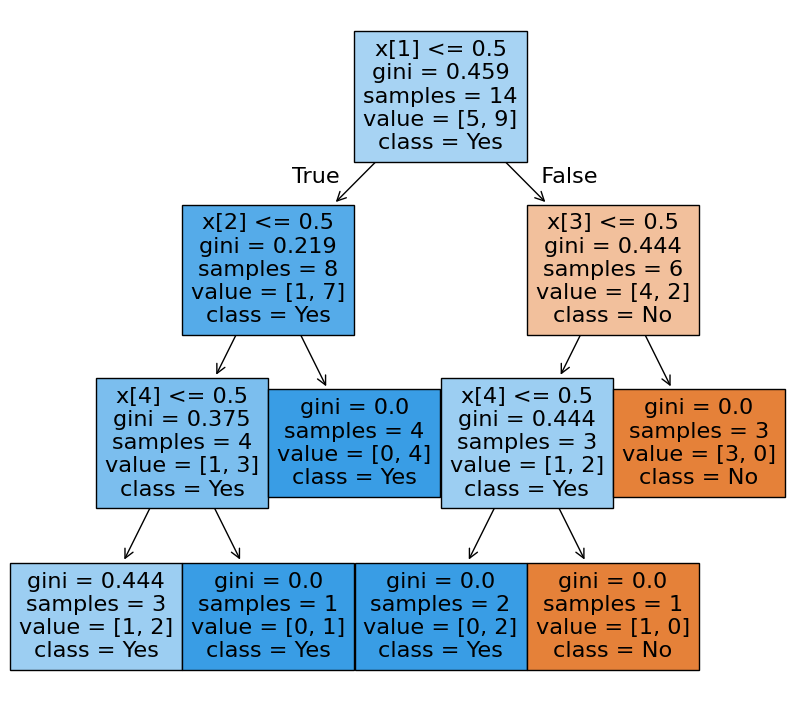

In [13]:
fig = plt.figure(figsize=(10, 9))
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True)
plt.show()

In [14]:
text_representation = tree.export_text(clf)
print(text_representation)

|--- feature_1 <= 0.50
|   |--- feature_2 <= 0.50
|   |   |--- feature_4 <= 0.50
|   |   |   |--- class: Yes
|   |   |--- feature_4 >  0.50
|   |   |   |--- class: Yes
|   |--- feature_2 >  0.50
|   |   |--- class: Yes
|--- feature_1 >  0.50
|   |--- feature_3 <= 0.50
|   |   |--- feature_4 <= 0.50
|   |   |   |--- class: Yes
|   |   |--- feature_4 >  0.50
|   |   |   |--- class: No
|   |--- feature_3 >  0.50
|   |   |--- class: No



In [15]:
new_data = pd.DataFrame({'Outlook': ['Sunny'], 'Temperature': ['Cold'], 'Humidity': ['High']})
transformed_new_data = encoder.transform(new_data)
print(clf.predict(transformed_new_data))
print(clf.predict_proba(transformed_new_data))

['No']
[[1. 0.]]


In [16]:
from sklearn import datasets
import numpy as np

iris = datasets.load_iris()
data = iris.data[:, [0, 1]]
target = iris.target
target[100:125] = 0
target[125:150] = 1

In [17]:
xtrain = np.concatenate((data[0:40], data[50:90], data[100:140]))
ytrain = np.concatenate((target[0:40], target[50:90], target[100:140]))

In [18]:
xtest = np.concatenate((data[40:50], data[90:100], data[140:150]))
ytest = np.concatenate((target[40:50], target[90:100], target[140:150]))

In [19]:
clf = tree.DecisionTreeClassifier(random_state=0, min_samples_split=20)
clf = clf.fit(xtrain, ytrain)

In [20]:
pred = clf.predict(xtest)

In [21]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
print(confusion_matrix(ytest, pred))
print(accuracy_score(ytest, pred))
print(precision_score(ytest, pred, pos_label=1))
print(recall_score(ytest, pred, pos_label=1))
print(f1_score(ytest, pred, pos_label=1))

[[ 9  1]
 [ 2 18]]
0.9
0.9473684210526315
0.9
0.9230769230769231


In [22]:
clf = tree.DecisionTreeClassifier(random_state=0, min_samples_split=10)
clf = clf.fit(xtrain, ytrain)
pred = clf.predict(xtest)
print(f1_score(ytest, pred, pos_label=1))

0.8648648648648649


In [23]:
clf = tree.DecisionTreeClassifier(random_state=0, min_samples_split=30)
clf = clf.fit(xtrain, ytrain)
pred = clf.predict(xtest)
print(f1_score(ytest, pred, pos_label=1))

0.95
